# 05. EDA comparativo entre los cuatro conjuntos

El enunciado pide un EDA por conjunto (notebooks 01 a 04) y uno comparativo. Aquí se ponen las cuatro estaciones
lado a lado: perfil y completitud, indicadores de calidad, uso de la columna `calidad`, relojes, la lluvia de la 367
frente a la 35 en el mismo sitio, la lluvia de la 35 frente al nivel de la 803 por eventos y la distancia entre
estaciones. Las correlaciones con rezagos y sobre series desestacionalizadas están en el notebook 08.

Todo se trabaja en hora local (UTC-5) salvo donde se diga "hora del archivo". Los CSV crudos no se modifican: se leen
con `siata.datos.cargar` y las series regularizadas con banderas salen de `python -m siata.pipeline`
(`parte2/salidas/minutal_<codigo>.parquet`). Los huecos no se interpolan en ningún gráfico.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.stats import spearmanr

from siata.datos import CENTINELAS, DIR_SALIDAS, ESTACIONES, RAIZ, cargar
from siata.calidad import geometria_solar
from siata.indicadores import SEMAFORO

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
DIR_FIG = RAIZ / "parte2" / "figuras"
DIR_RES = RAIZ / "parte2" / "resultados"
DIR_FIG.mkdir(exist_ok=True)

# Un color y un marcador fijos por estación en todos los gráficos (paleta apta para daltonismo)
COLOR = {"367": "#2a78d6", "35": "#eb6834", "803": "#1baf7a", "6004": "#eda100"}
MARCA = {"367": "o", "35": "s", "803": "^", "6004": "D"}
GRIS = "#6b6a66"
MESES = "ene feb mar abr may jun jul ago sep oct nov dic".split()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e3e3e0", "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10,
                     "axes.titlelocation": "left", "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 8, "lines.linewidth": 1.6})


def eje_meses(eje):
    eje.xaxis.set_major_locator(mdates.MonthLocator())
    eje.xaxis.set_major_formatter(plt.FuncFormatter(
        lambda x, _: f"{MESES[mdates.num2date(x).month - 1]} {mdates.num2date(x).year}"))


def coma(x, decimales=1):
    """Número con coma decimal para títulos y etiquetas de las figuras."""
    return f"{x:.{decimales}f}".replace(".", ",")


def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"05_{nombre}.png", dpi=110, bbox_inches="tight")


def huecos(presente):
    """Rachas de minutos sin registro: inicio y duración en minutos."""
    falta = ~presente
    grupo = (falta != falta.shift()).cumsum()[falta]
    t = presente.index.to_series()[falta]
    return pd.DataFrame({"inicio": t.groupby(grupo).min(), "minutos": t.groupby(grupo).size()}).reset_index(drop=True)

In [2]:
crudo = {c: cargar(c) for c in ESTACIONES}
faltan = [c for c in ESTACIONES if not (DIR_SALIDAS / f"minutal_{c}.parquet").exists()]
assert not faltan, f"Faltan salidas del pipeline para {faltan}: corra 'python -m siata.pipeline' desde parte2/"
# Serie minutal regularizada en hora local, con calidad de SIATA y banderas propias (b_*)
minutal = {c: pd.read_parquet(DIR_SALIDAS / f"minutal_{c}.parquet") for c in ESTACIONES}
FILAS_ENUNCIADO = {"367": 217_397, "803": 217_318, "6004": 214_824, "35": 217_440}
{c: (len(crudo[c]), len(minutal[c])) for c in ESTACIONES}

{'367': (217397, 217440),
 '803': (217318, 217440),
 '6004': (214824, 217440),
 '35': (217440, 217440)}

## 1. Perfil y completitud lado a lado

Misma tabla para los cuatro archivos. "Minutos sin registro" cuenta los minutos de la malla esperada (151 días,
217 440 minutos) que no llegaron; el -999 se cuenta aparte porque la fila sí llegó, pero sin valor. La resolución es
el paso mínimo entre valores distintos.

In [3]:
def resolucion(s):
    u = np.sort(s[~s.isin(CENTINELAS)].dropna().unique())
    paso = np.diff(u)
    return round(float(paso[paso > 1e-9].min()), 3)


filas = {}
for c, df in crudo.items():
    d, h = minutal[c], huecos(minutal[c]["presente"])
    filas[c] = {
        "tipo": ESTACIONES[c]["tipo"],
        "filas": len(df), "filas según enunciado": FILAS_ENUNCIADO[c],
        "duplicados (codigo, fecha_hora)": int(df.duplicated(["codigo", "fecha_hora"]).sum()),
        "ordenado": bool(df["fecha_hora"].is_monotonic_increasing),
        "nulos": int(df.isna().sum().sum()),
        "marcas fuera del minuto": int((df["fecha_hora"].dt.second != 0).sum()),
        "minutos sin registro": int((~d["presente"]).sum()),
        "completitud de filas %": round(100 * d["presente"].mean(), 2),
        "huecos": len(h),
        "hueco más largo (min)": int(h["minutos"].max()) if len(h) else 0,
        "huecos > 60 min": int((h["minutos"] > 60).sum()),
        "minutos con -999": int(d["centinela"].sum()),
        "resolución": ", ".join(f"{v} {resolucion(df[v])}" for v in ESTACIONES[c]["variables"]),
        "códigos de calidad distintos": df["calidad"].nunique(),
        "reloj del archivo": "UTC" if ESTACIONES[c]["utc_archivo"] == 0 else "UTC-5 (local)",
        "primer minuto (hora local)": d.index.min(),
        "último minuto (hora local)": d.index.max(),
    }
perfil = pd.DataFrame(filas)
perfil

,367,803,6004,35
tipo,Meteorológica,Nivel,Piranómetro,Pluviométrica
filas,217397,217318,214824,217440
filas según enunciado,217397,217318,214824,217440
"duplicados (codigo, fecha_hora)",0,0,0,0
ordenado,True,True,True,True
nulos,0,0,0,0
marcas fuera del minuto,0,0,15,0
minutos sin registro,43,122,2617,0
completitud de filas %,99.98,99.94,98.8,100.0
huecos,22,20,207,0


In [4]:
# Minutos sin dato (sin fila o con -999) en la ventana común de las cuatro estaciones
comun = minutal["367"].index.intersection(minutal["6004"].index)
sin_dato = pd.DataFrame({c: (~d["presente"] | d["centinela"]).reindex(comun) for c, d in minutal.items()})
n = sin_dato.sum(axis=1)
print("ventana común en hora local:", comun.min(), "a", comun.max())
print("minutos sin dato en dos o más estaciones:", int((n >= 2).sum()), "| en las tres de La Ladera (367, 35, 803):",
      int(sin_dato[["367", "35", "803"]].all(axis=1).sum()))
cent = minutal["35"].index[minutal["35"]["centinela"]]
for c in ["367", "803"]:
    falta = minutal[c].index[~minutal[c]["presente"]]
    print(f"minutos con -999 en la 35 que tampoco tienen fila en la {c}: {cent.isin(falta).sum()} de {len(cent)}")
print("códigos de calidad de la 35 en esos minutos:", crudo["35"].set_index("fecha_hora").loc[cent, "calidad"].unique())
sin_dato[n >= 2].assign(estaciones=n[n >= 2])

ventana común en hora local: 2025-12-01 00:00:00 a 2026-04-30 18:59:00
minutos sin dato en dos o más estaciones: 10 | en las tres de La Ladera (367, 35, 803): 6
minutos con -999 en la 35 que tampoco tienen fila en la 367: 7 de 7
minutos con -999 en la 35 que tampoco tienen fila en la 803: 6 de 7
códigos de calidad de la 35 en esos minutos: [151]


,367,803,6004,35,estaciones
fecha_hora,,,,,
2026-01-08 11:26:00,True,True,False,True,3
2026-01-08 11:35:00,True,True,False,True,3
2026-01-08 11:47:00,True,True,False,False,2
2026-01-08 11:59:00,True,True,False,True,3
2026-01-08 12:01:00,True,False,False,True,2
2026-01-08 13:17:00,True,True,False,False,2
2026-01-08 16:16:00,True,True,False,True,3
2026-01-08 16:17:00,True,True,False,True,3
2026-03-22 00:26:00,True,True,False,False,2


In [5]:
# Huecos de la 367: casi todos empiezan en el minuto 1 de la hora
f367 = minutal["367"].index[~minutal["367"]["presente"]]
print("minutos sin registro de la 367 por minuto de la hora:", pd.Series(f367.minute).value_counts().head(4).to_dict())
h6004 = huecos(minutal["6004"]["presente"])
print(f"6004: {len(h6004)} huecos, {(h6004.minutos == 1).sum()} de un solo minuto; los más largos:")
h6004.sort_values("minutos", ascending=False).head(4)

minutos sin registro de la 367 por minuto de la hora: {1: 12, 2: 12, 26: 2, 47: 2}
6004: 207 huecos, 134 de un solo minuto; los más largos:


,inicio,minutos
201,2026-04-08 05:41:00,1752
34,2025-12-23 08:19:00,211
15,2025-12-05 17:48:00,72
206,2026-04-28 08:08:00,66


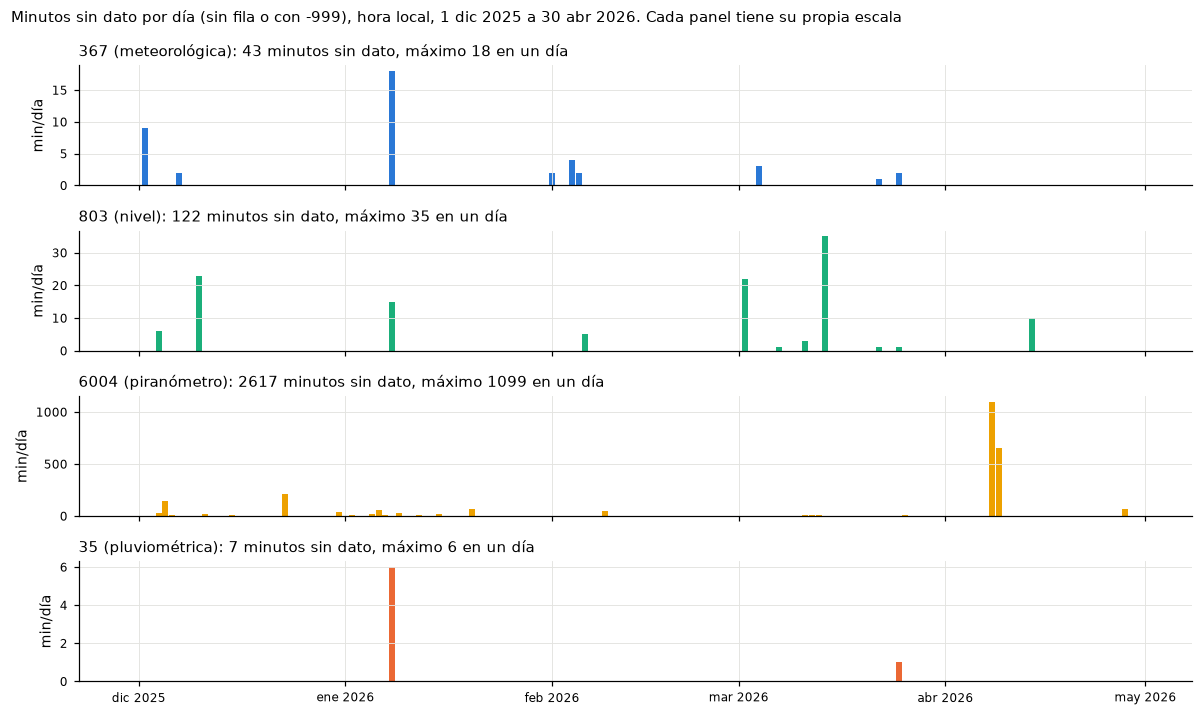

In [6]:
fig, ejes = plt.subplots(4, 1, figsize=(11, 6.6), sharex=True)
for eje, c in zip(ejes, ESTACIONES):
    d = minutal[c]
    diario = (~d["presente"] | d["centinela"]).resample("D").sum()
    eje.bar(diario.index, diario.to_numpy(), width=0.9, color=COLOR[c])
    eje.set_ylim(bottom=0)
    eje.set_ylabel("min/día")
    eje.set_title(f"{c} ({ESTACIONES[c]['tipo'].lower()}): {int(diario.sum())} minutos sin dato, "
                  f"máximo {int(diario.max())} en un día")
eje_meses(ejes[-1])
fig.suptitle("Minutos sin dato por día (sin fila o con -999), hora local, 1 dic 2025 a 30 abr 2026. "
             "Cada panel tiene su propia escala", x=0.01, ha="left", fontsize=10)
fig.tight_layout()

Lectura de la sección 1 (cifras de las salidas de arriba):

- Los cuatro archivos tienen las filas que dice el enunciado, sin duplicados, ordenados y sin nulos. Las tres
  estaciones de La Ladera están casi completas: la 35 no pierde ninguna fila, la 367 pierde 43 minutos (hueco más
  largo de 4 min) y la 803 pierde 122 (hueco más largo de 35 min). La 6004 es el conjunto débil: 2617 minutos sin
  registro, 207 huecos (134 de un solo minuto), 4 de más de una hora y uno de 1752 minutos (8 y 9 de abril de 2026).
- La misma falla se escribe de dos formas. Los 7 minutos con -999 de la 35 (código 151) son minutos en los que la 367
  tampoco tiene fila (7 de 7) y la 803 tampoco (6 de 7). Es decir, hubo una falla común del sitio o de la transmisión
  (8 ene y 25 mar de 2026, inferido), y un archivo la guarda como -999 y los otros dos como fila ausente. Quien cuente
  faltantes solo por filas ausentes dirá que la 35 está completa al 100 %, y no lo está.
- Los huecos de la 367 caen sobre todo en los minutos 1 y 2 de la hora (24 de 43). Parece un proceso horario del
  registrador o de la transmisión (inferido, no hay documentación).
- La resolución cambia entre archivos y entre sensores de la misma variable: la lluvia de la 367 viene en pasos de
  0,01 mm y la de la 35 en pasos de 0,254 mm. Para comparar ocurrencia hay que usar el mismo umbral (sección 5).
- La ventana común de las cuatro termina el 30 abr a las 18:59 hora local, porque la 6004 está en UTC
  (sección 4): sus últimas 5 horas locales del 30 de abril no están en el archivo y sus primeras 5 caen el 30 de
  noviembre.

## 2. Indicadores de calidad comparados

Los tres indicadores de la pregunta 1.3, calculados por `siata.pipeline` y guardados en `parte2/resultados/`:
completitud (minutos con valor sobre minutos esperados), proporción de válidos (de lo recibido, cuánto pasa todas las
reglas deterministas) y confiabilidad de la bandera (kappa de Cohen entre "SIATA lo marca dudoso" y "el control propio
no lo da por bueno"). Umbrales del semáforo en `siata.indicadores.SEMAFORO`.

In [7]:
periodo = pd.read_csv(DIR_RES / "indicadores_periodo.csv", dtype={"codigo": str})
mensual = pd.read_csv(DIR_RES / "indicadores_mensuales.csv", dtype={"codigo": str}, parse_dates=["mes"])
print("semáforo (aceptable, alerta):", SEMAFORO)
tabla = periodo.assign(completitud=100 * periodo["completitud"], validos=100 * periodo["validos"],
                       falsos_confiables=100 * periodo["falsos_confiables"],
                       dudosos_que_pasan=100 * periodo["dudosos_que_pasan"])
tabla.rename(columns={"completitud": "completitud %", "validos": "válidos %",
                      "falsos_confiables": "confiables SIATA que fallan el control %",
                      "dudosos_que_pasan": "dudosos SIATA que pasan el control %"}).round(3)

semáforo (aceptable, alerta): {'completitud': (0.95, 0.8), 'validos': (0.98, 0.9), 'kappa': (0.61, 0.41)}


,codigo,variable,completitud %,válidos %,kappa,kappa_max,confiables SIATA que fallan el control %,dudosos SIATA que pasan el control %,semaforo_completitud,semaforo_validos,semaforo_kappa
0,367,h,99.980,99.159,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
1,367,t,99.980,99.943,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
2,367,pr,99.980,99.810,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
3,367,vv,99.980,98.929,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
4,367,vv_max,99.980,99.969,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
5,367,dv,99.980,99.969,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
6,367,dv_max,99.980,99.979,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
7,367,p,99.980,99.605,0.053,0.215,2.485,73.431,aceptable,aceptable,crítico
8,803,nivel,99.944,96.368,0.419,0.431,0.098,70.622,aceptable,alerta,alerta
9,6004,radiacion,98.796,99.983,0.008,0.042,0.014,99.595,aceptable,aceptable,crítico


completitud                         validos                           kappa                        
codigo              35     367    6004     803      35     367    6004     803      35     367    6004     803
mes                                                                                                           
2025-12-01      1.0000  0.9998  0.9896  0.9994  0.9989  0.9914  0.9998  0.9084 -0.0004  0.0000  0.0556  0.5263
2026-01-01      0.9999  0.9996  0.9948  0.9997  0.9987  0.9857  0.9999  1.0000 -0.0007  0.0397  0.0132  0.0000
2026-02-01      1.0000  0.9998  0.9985  0.9999  0.9999  0.9842  0.9997  1.0000  0.4137  0.0744  0.0033  0.0000
2026-03-01      1.0000  0.9999  0.9992  0.9986  0.9999  0.9894  1.0000  0.9146  0.4137  0.0651  0.0000  0.6771
2026-04-01      1.0000  1.0000  0.9575  0.9998  0.9985  0.9878  0.9997  1.0000 -0.0009  0.0689 -0.0007 -0.0001

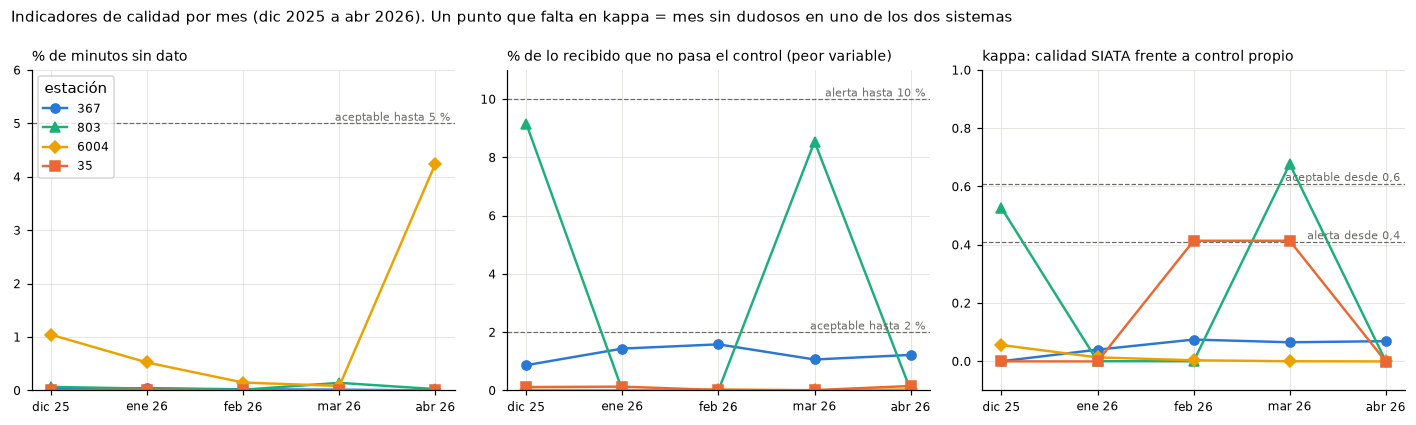

In [8]:
# Por estación y mes: completitud y válidos de la peor variable; kappa es por registro (igual para todas)
m = mensual[mensual["mes"] >= "2025-12-01"]  # la 6004 tiene 5 h del 30 nov en hora local: se deja fuera del gráfico
por_estacion = m.groupby(["codigo", "mes"]).agg(completitud=("completitud", "min"), validos=("validos", "min"),
                                                kappa=("kappa", "first"))
meses = sorted(m["mes"].unique())
x = np.arange(len(meses))
umbral = {k: SEMAFORO[k] for k in SEMAFORO}
paneles = [
    ("completitud", "% de minutos sin dato", lambda s: 100 * (1 - s),
     [(100 * (1 - umbral["completitud"][0]), "aceptable hasta 5 %")], (0, 6)),
    ("validos", "% de lo recibido que no pasa el control (peor variable)", lambda s: 100 * (1 - s),
     [(100 * (1 - umbral["validos"][0]), "aceptable hasta 2 %"), (100 * (1 - umbral["validos"][1]), "alerta hasta 10 %")],
     (0, 11)),
    ("kappa", "kappa: calidad SIATA frente a control propio", lambda s: s,
     [(umbral["kappa"][0], "aceptable desde 0,6"), (umbral["kappa"][1], "alerta desde 0,4")], (-0.1, 1)),
]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.9))
for eje, (col, titulo, f, lineas, lim) in zip(ejes, paneles):
    for y, texto in lineas:
        eje.axhline(y, color=GRIS, lw=0.8, ls="--")
        eje.text(x[-1] + 0.15, y, texto, fontsize=7, color=GRIS, va="bottom", ha="right")
    for c in ESTACIONES:
        s = f(por_estacion.loc[c, col].reindex(meses))
        eje.plot(x, s.to_numpy(), marker=MARCA[c], ms=6, color=COLOR[c], label=c)
    eje.set_xticks(x, [f"{MESES[pd.Timestamp(mm).month - 1]} {pd.Timestamp(mm).year % 100}" for mm in meses])
    eje.set_ylim(*lim)
    eje.set_title(titulo, fontsize=9)
ejes[0].legend(title="estación", loc="upper left")
fig.suptitle("Indicadores de calidad por mes (dic 2025 a abr 2026). Un punto que falta en kappa = mes sin dudosos "
             "en uno de los dos sistemas", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
guardar(fig, "indicadores_mensuales")
por_estacion.unstack("codigo").round(4)

Lectura de la sección 2:

- Completitud: las cuatro están en aceptable en el periodo (98,8 % o más). La única que se acerca al límite es la
  6004 en abril (4,25 % de minutos sin dato, casi todo por el hueco de 1752 minutos).
- Válidos: la 803 es la única en alerta en el periodo (96,4 %), y no de forma pareja: diciembre baja a 90,8 % y
  marzo a 91,5 % (mesetas de nivel sin lluvia, sección 6) y enero, febrero y abril quedan en 100 %. En la 367 la peor
  variable es la velocidad del viento (98,9 %), sobre todo por persistencias.
- Kappa: la bandera de SIATA y el control propio casi no coinciden en la 367 (0,053), la 6004 (0,008) y la 35
  (0,068). La 803 es la única con acuerdo moderado (0,42 en el periodo, 0,53 en diciembre y 0,68 en marzo). Un kappa
  cercano a cero indica que los dos sistemas marcan cosas distintas, sin decir cuál está bien. Por ejemplo, en la
  6004 el 99,6 % de lo que SIATA marca dudoso pasa el control propio (los 1582 del amanecer y el atardecer
  y casi todos los 1583, sección 3). En la 367 pasa el 73,4 % de lo que SIATA marca, mientras que el 2,5 % de lo que SIATA publica
  como confiable no pasa (sobre todo persistencias de viento y humedad). Este indicador es el que justifica no
  usar la columna `calidad` como verdad.

## 3. Uso de la columna `calidad` en cada estación

Con los datos no viene un diccionario. La ficha de la 6004 en el repositorio de SIATA documenta los códigos del
piranómetro (1 confiable en tiempo real, 151 dudoso, 1581, 1582 y 1583 de radiación) y el diccionario oficial de cada
red está en sus guías "Generalidades Repositorio de Datos", aparte de las fichas; el contraste con lo inferido está en
el notebook 07. Aquí se compara qué códigos usa cada estación, cuánto y cuándo.

In [9]:
conteo = pd.DataFrame({c: crudo[c]["calidad"].value_counts() for c in ESTACIONES}).fillna(0).astype(int).sort_index()
conteo.index.name = "código"
print("% de registros con código distinto de 1:", (100 - 100 * conteo.loc[1] / conteo.sum()).round(2).to_dict())
conteo

% de registros con código distinto de 1: {'367': 0.32, '803': 12.09, '6004': 0.81, '35': 1.4}


,367,803,6004,35
código,,,,
1,216712,191042,213093,214388
2,0,42,0,2944
151,0,7955,0,9
154,105,0,0,0
251,0,394,0,1
1502,0,14333,0,0
1504,0,2987,0,0
1511,508,0,0,43
1512,0,0,0,54


In [10]:
filas = []
for c in ESTACIONES:
    d = minutal[c][minutal[c]["presente"]]
    for k, g in d[d["calidad"] != 1].groupby("calidad"):
        filas.append({"estación": c, "código": int(k), "registros": len(g),
                      "días con el código": g.index.normalize().nunique(),
                      "primero (hora local)": g.index.min(), "último (hora local)": g.index.max()})
pd.DataFrame(filas)

,estación,código,registros,días con el código,primero (hora local),último (hora local)
0,367,154,105,2,2026-01-31 05:18:00,2026-02-25 05:03:00
1,367,1511,508,60,2026-01-01 10:39:00,2026-04-29 16:21:00
2,367,1567,72,4,2026-03-04 14:20:00,2026-04-27 15:16:00
3,803,2,42,15,2026-01-08 12:05:00,2026-03-02 11:58:00
4,803,151,7955,47,2025-12-02 18:10:00,2026-04-30 23:30:00
5,803,251,394,2,2025-12-04 09:35:00,2025-12-07 06:33:00
6,803,1502,14333,146,2025-12-01 05:26:00,2026-04-30 22:27:00
7,803,1504,2987,28,2025-12-02 07:17:00,2025-12-31 07:34:00
8,803,2502,565,10,2025-12-13 13:10:00,2026-02-18 14:23:00
9,6004,1582,977,108,2025-12-01 05:58:00,2026-04-30 18:04:00


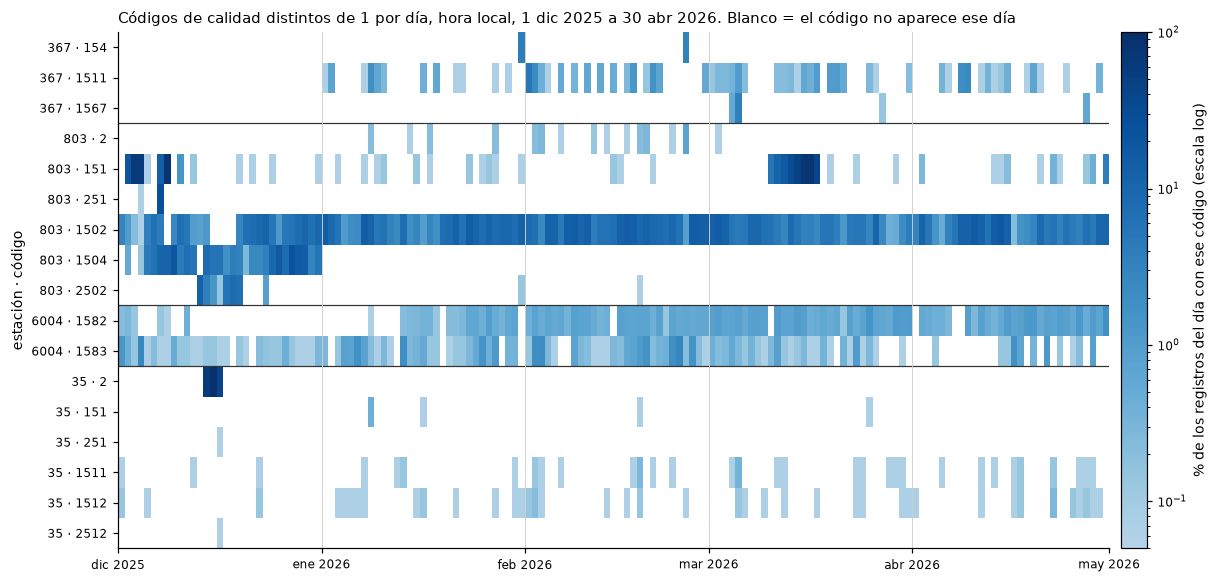

In [11]:
# Raster: % de los registros de cada día que lleva cada código distinto de 1
filas, etiquetas, cortes = [], [], []
for c in ESTACIONES:
    d = minutal[c][minutal[c]["presente"]]
    total = d["calidad"].resample("D").size()
    for k in sorted(d.loc[d["calidad"] != 1, "calidad"].unique()):
        filas.append(100 * (d["calidad"] == k).resample("D").sum() / total)
        etiquetas.append(f"{c} · {int(k)}")
    cortes.append(len(filas))
R = pd.concat(filas, axis=1, sort=True).T
R = R.loc[:, R.columns >= "2025-12-01"]
dias = R.columns
bordes = mdates.date2num(list(dias) + [dias[-1] + pd.Timedelta("1D")])
azul = LinearSegmentedColormap.from_list("azul", plt.cm.Blues(np.linspace(0.3, 1, 256)))

fig, eje = plt.subplots(figsize=(12, 5.4))
malla = eje.pcolormesh(bordes, np.arange(len(R) + 1), np.ma.masked_invalid(R.where(R > 0).to_numpy(dtype=float)),
                       cmap=azul, norm=LogNorm(vmin=0.05, vmax=100), shading="flat")
eje.grid(False)
for corte in cortes[:-1]:
    eje.axhline(corte, color="#333333", lw=0.8)
for mes in pd.date_range("2026-01-01", "2026-04-01", freq="MS"):
    eje.axvline(mdates.date2num(mes), color="#cfcfcb", lw=0.6)
eje.set_yticks(np.arange(len(R)) + 0.5, etiquetas)
eje.invert_yaxis()
eje.xaxis_date()
eje_meses(eje)
eje.set_ylabel("estación · código")
barra = fig.colorbar(malla, ax=eje, pad=0.01)
barra.set_label("% de los registros del día con ese código (escala log)")
eje.set_title("Códigos de calidad distintos de 1 por día, hora local, 1 dic 2025 a 30 abr 2026. Blanco = el código no aparece ese día")
fig.tight_layout()
guardar(fig, "calidad_en_el_tiempo")

¿Las reglas de SIATA son las mismas durante todo el periodo? Se cuentan, por mes, los casos que cumplen la condición
que parece describir cada código y cuántos de ellos lo llevan. Las condiciones son inferidas a partir de los datos
(notebooks 01 a 04); si el código fuera una regla fija, la fracción marcada sería estable mes a mes.

In [12]:
m367, m803, m6004, m35 = (minutal[c] for c in ["367", "803", "6004", "35"])
lluvia_35_vecina = m35["p1"].fillna(0).rolling(21, center=True, min_periods=1).sum()  # ±10 min
viento_cero = (m367[["vv", "vv_max", "dv", "dv_max"]] == 0).all(axis=1)
mins_6004 = m6004.index.hour * 60 + m6004.index.minute
ventana_noche = pd.Series((mins_6004 >= 18 * 60) | (mins_6004 < 6 * 60), index=m6004.index)
reglas = {
    ("803", "nivel < 0", 1504): (m803["nivel"] < 0, m803["calidad"] == 1504),
    ("367", "p = 0,01 mm y la 35 en cero ±10 min", 1511): ((m367["p"] == 0.01) & (lluvia_35_vecina == 0),
                                                           m367["calidad"] == 1511),
    ("367", "h = 100 %", 154): (m367["h"] == 100, m367["calidad"] == 154),
    ("367", "vv, vv_max, dv y dv_max en 0", 1567): (viento_cero, m367["calidad"] == 1567),
    ("6004", "radiación > 0 entre 18:00 y 06:00 local", 1582): (ventana_noche & (m6004["radiacion"] > 0),
                                                                m6004["calidad"] == 1582),
}
periodos = pd.period_range("2025-12", "2026-04", freq="M")
por_mes = lambda s: s.groupby(s.index.to_period("M")).sum().reindex(periodos, fill_value=0)
filas, cumple = {}, {}
for (c, condicion, codigo), (caso, marca) in reglas.items():
    filas[(c, codigo, condicion, "casos")] = por_mes(caso)
    filas[(c, codigo, condicion, "con el código")] = por_mes(caso & marca)
    filas[(c, codigo, condicion, "% de casos con el código")] = (100 * por_mes(caso & marca) / por_mes(caso)).round(1)
    cumple[(c, codigo, condicion)] = {"registros con el código": int(marca.sum()),
                                      "% de ellos que cumple la condición": round(100 * caso[marca].mean(), 1)}
cambios = pd.DataFrame(filas).T
cambios.columns = [str(p) for p in cambios.columns]
display(pd.DataFrame(cumple).T)
cambios

registros con el código  % de ellos que cumple la condición
803  1504 nivel < 0                                                 2987.0                               100.0
367  1511 p = 0,01 mm y la 35 en cero ±10 min                        508.0                                87.8
     154  h = 100 %                                                  105.0                               100.0
     1567 vv, vv_max, dv y dv_max en 0                                72.0                                63.9
6004 1582 radiación > 0 entre 18:00 y 06:00 local                    977.0                                97.4

2025-12  2026-01  2026-02  2026-03  2026-04
803  1504 nivel < 0                               casos                      2988.0   2570.0   3159.0    745.0   2218.0
                                                  con el código              2987.0      0.0      0.0      0.0      0.0
                                                  % de casos con el código    100.0      0.0      0.0      0.0      0.0
367  1511 p = 0,01 mm y la 35 en cero ±10 min     casos                       307.0    510.0    390.0    678.0    430.0
                                                  con el código                 0.0     67.0    178.0    116.0     85.0
                                                  % de casos con el código      0.0     13.1     45.6     17.1     19.8
     154  h = 100 %                               casos                        64.0    546.0    547.0    103.0    103.0
                                                  con el código                 0.0     57.0     48.0      0.0      0.0
                                                  % de casos con el código      0.0     10.4      8.8      0.0      0.0
     1567 vv, vv_max, dv y dv_max en 0            casos                         0.0      0.0      0.0     37.0      9.0
                                                  con el código                 0.0      0.0      0.0     37.0      9.0
                                                  % de casos con el código      NaN      NaN      NaN    100.0    100.0
6004 1582 radiación > 0 entre 18:00 y 06:00 local casos                        12.0    103.0    237.0    338.0    262.0
                                                  con el código                12.0    103.0    237.0    338.0    262.0
                                                  % de casos con el código    100.0    100.0    100.0    100.0    100.0

Lectura de la sección 3:

- Cada estación usa su propio juego de códigos y la cantidad es muy distinta: 0,3 % de registros con código distinto
  de 1 en la 367, 0,8 % en la 6004, 1,4 % en la 35 y 12,1 % en la 803. Un mismo número aparece en varias estaciones
  (151, 251, 2, 1511) y no siempre significa lo mismo: según las guías de cada red, 1511 es la lluvia `p` en la 367 y
  el balancín p1 en la 35 (notebook 07).
- Las reglas no son estables en el tiempo. El 1504 marca casi todos los niveles negativos de diciembre (2987 de 2988) y
  ninguno de los 8692 de enero a abril. El 1511 de la 367 no aparece en diciembre aunque hay 307
  casos con la misma condición, y de enero a abril marca entre 13 % y 46 % de ellos. El 154 solo aparece en enero y
  febrero, y aun ahí solo en cerca del 10 % de los minutos con humedad en 100 %, que hay todos los meses. Esto apunta a cambios del algoritmo o a revisiones manuales
  parciales durante el periodo (inferido). Hay reglas que sí se ven fijas: el 1582 de la 6004 cubre todos los
  minutos con radiación mayor que 0 entre las 18:00 y las 05:59 hora local (952 de 952; con el minuto de las 06:00 son los 977 de 977, como en el notebook 03). Es una ventana de reloj y no
  de posición del sol, y por eso marca amaneceres y atardeceres con el sol todavía arriba.
- Los códigos tienen estructura. La regla del primer dígito está documentada (P-GAA-SIATA-108, p. 5): 1 para tiempo real y 2 para no
  tiempo real. Así, 2502, 251 y 2512 serían las versiones "2" de 1502, 151 y 1512, y el 2 de la 35 son los 2944 minutos
  del 14 al 16 dic, que según la guía de la red pluviométrica (P-GAA-SIATA-107, Tabla 4, p. 6) es dato confiable no obtenido en tiempo real. El 15 inicial sería
  "dudoso" y el dígito siguiente parece ir con el tipo de variable (0 nivel en la 803, 1 lluvia en la 367 y la 35,
  6 viento en la 367, 8 radiación en la 6004). Las condiciones tampoco describen los códigos por completo: el 87,8 %
  de los 1511 de la 367 cumple la condición de la tabla y el 63,9 % de los 1567.
- Que el diccionario no venga con los datos significa, en la práctica, que un usuario no puede filtrar con criterio: no sabe si un 151
  de la 803 (meseta de horas) pesa lo mismo que un 151 de la 35 (casi siempre un minuto con -999), ni qué versión del
  algoritmo marcó cada dato. Por eso aquí la columna se trata como etiqueta débil y el control propio no depende de
  ella.

## 4. Alineación de relojes

Supuesto S1 del informe: la 6004 viene en UTC y las otras tres en hora local. Aquí se pone a prueba con tres
evidencias independientes: el ciclo diurno frente a la temperatura de la 367, la radiación extraterrestre y la propia
regla 1582 de SIATA. Se usa a propósito el ciclo diurno compartido: aquí el ciclo es la señal que delata el reloj, no
una relación entre variables.

In [13]:
e6004 = ESTACIONES["6004"]
r_archivo = crudo["6004"].assign(fecha_hora=crudo["6004"]["fecha_hora"].dt.floor("min")) \
    .drop_duplicates("fecha_hora").set_index("fecha_hora")["radiacion"]  # tal cual, en hora del archivo
r_local = m6004["radiacion"]
t367 = m367["t"]


def ciclo(s, paso=10):
    """Ciclo medio en pasos de 10 min, escalado a 0 (mínimo) y 1 (máximo)."""
    c = s.groupby((s.index.hour * 60 + s.index.minute) // paso * paso).mean()
    return (c - c.min()) / (c.max() - c.min())


sol_local = geometria_solar(r_local.index, e6004["lat"], e6004["lon"])
cos_z = sol_local["cos_z"].clip(lower=0)
pico = lambda c: c.idxmax() / 60
ciclos = {"archivo": ciclo(r_archivo), "local": ciclo(r_local)}
print(f"pico medio de radiación 6004: {pico(ciclos['archivo']):.2f} h del archivo, {pico(ciclos['local']):.2f} h local")
print(f"pico medio de temperatura 367: {pico(ciclo(t367)):.2f} h | máximo medio del sol teórico en la 6004: "
      f"{pico(ciclo(cos_z)):.2f} h local")

# Correlación cruzada horaria: en qué desfase la temperatura de la 367 se parece más a la radiación
th = t367.resample("h").mean()
desfases = range(-8, 9)
cc = pd.DataFrame({nombre: {k: th.corr(s.resample("h").mean().shift(k)) for k in desfases}
                   for nombre, s in [("radiación en hora del archivo", r_archivo), ("radiación en hora local", r_local)]})
print("desfase de máxima correlación (horas; positivo = la temperatura va detrás de la radiación):",
      cc.idxmax().to_dict())
cc.round(3).T

pico medio de radiación 6004: 17.33 h del archivo, 12.33 h local
pico medio de temperatura 367: 13.67 h | máximo medio del sol teórico en la 6004: 12.00 h local
desfase de máxima correlación (horas; positivo = la temperatura va detrás de la radiación): {'radiación en hora del archivo': -3, 'radiación en hora local': 2}


,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
radiación en hora del archivo,0.028,0.269,0.512,0.711,0.830,0.847,0.780,0.653,0.490,0.313,0.142,-0.006,-0.127,-0.227,-0.307,-0.373,-0.432
radiación en hora local,-0.564,-0.547,-0.482,-0.363,-0.189,0.028,0.269,0.512,0.711,0.830,0.848,0.781,0.653,0.490,0.313,0.141,-0.007


In [14]:
# Radiación por encima de la extraterrestre horizontal (S0 · cos z) según cómo se lea el reloj
def sobre_extraterrestre(radiacion, indice_local):
    sol = geometria_solar(indice_local, e6004["lat"], e6004["lon"])
    return int((radiacion.to_numpy() > (sol["sa"] * sol["cos_z"].clip(lower=0)).to_numpy()).sum())

print("minutos sobre la radiación extraterrestre si el archivo estuviera en hora local:",
      sobre_extraterrestre(r_archivo, r_archivo.index))
print("minutos sobre la radiación extraterrestre si el archivo está en UTC:",
      sobre_extraterrestre(r_archivo, r_archivo.index - pd.Timedelta(hours=5)))
# La regla 1582 ("mayor a 0 de noche") de SIATA: ¿en qué reloj trabaja?
es_1582 = m6004["calidad"] == 1582
caso_local = ventana_noche & (m6004["radiacion"] > 0)
print(f"radiación > 0 entre 18:00 y 06:00 hora local: {int(caso_local.sum())} minutos, con 1582: "
      f"{int((caso_local & es_1582).sum())}; de los 1582, dentro de esa ventana: {ventana_noche[es_1582].mean():.1%}")
# La misma ventana leída en el reloj del archivo equivale a 13:00-01:00 local: incluiría toda la tarde soleada
hora_archivo = (m6004.index + pd.Timedelta(hours=5)).hour
caso_archivo = pd.Series((hora_archivo >= 18) | (hora_archivo < 6), index=m6004.index) & (m6004["radiacion"] > 0)
print(f"radiación > 0 entre 18:00 y 06:00 en hora del archivo: {int(caso_archivo.sum())} minutos, con 1582: "
      f"{int((caso_archivo & es_1582).sum())} ({(caso_archivo & es_1582).sum() / caso_archivo.sum():.1%})")

minutos sobre la radiación extraterrestre si el archivo estuviera en hora local: 63861
minutos sobre la radiación extraterrestre si el archivo está en UTC: 1162
radiación > 0 entre 18:00 y 06:00 hora local: 952 minutos, con 1582: 952; de los 1582, dentro de esa ventana: 97.4%
radiación > 0 entre 18:00 y 06:00 en hora del archivo: 44971 minutos, con 1582: 832 (1.9%)


In [15]:
# 367 y 35: mismo reloj al minuto. Correlación de la lluvia minutal y a 5 min con desfases
lluvia = pd.DataFrame({"p": m367["p"], "p1": m35["p1"], "p2": m35["p2"]})
cinco = lluvia.resample("5min").sum(min_count=5)
pd.DataFrame({"1 min": {k: lluvia["p"].corr(lluvia["p1"].shift(-k)) for k in range(-3, 4)},
              "5 min": {k: cinco["p"].corr(cinco["p1"].shift(-k)) for k in range(-3, 4)}}).rename_axis(
    "desfase (pasos; positivo = la 35 va detrás)").round(3)

,1 min,5 min
desfase (pasos; positivo = la 35 va detrás),,
-3,0.694,0.381
-2,0.752,0.535
-1,0.828,0.757
0,0.883,0.973
1,0.834,0.777
2,0.769,0.560
3,0.711,0.400


In [16]:
# Marcas de la 6004 con segundos distintos de cero: día y hora
fuera = crudo["6004"].loc[crudo["6004"]["fecha_hora"].dt.second != 0, "fecha_hora"]
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
local = fuera - pd.Timedelta(hours=5)
anterior_falta = [not bool(m6004["presente"].get(t.floor("min") - pd.Timedelta("1min"), True)) for t in local]
pd.DataFrame({"archivo (UTC)": fuera.to_numpy(), "día UTC": fuera.dt.day_of_week.map(dict(enumerate(DIAS))).to_numpy(),
              "hora local": local.to_numpy(), "día local": local.dt.day_of_week.map(dict(enumerate(DIAS))).to_numpy(),
              "el minuto anterior no tiene registro": anterior_falta})

,archivo (UTC),día UTC,hora local,día local,el minuto anterior no tiene registro
0,2025-12-01 03:02:23,lunes,2025-11-30 22:02:23,domingo,True
1,2025-12-15 03:03:20,lunes,2025-12-14 22:03:20,domingo,False
2,2025-12-22 03:01:16,lunes,2025-12-21 22:01:16,domingo,False
3,2025-12-31 15:20:22,miércoles,2025-12-31 10:20:22,miércoles,True
4,2026-01-12 03:02:10,lunes,2026-01-11 22:02:10,domingo,True
5,2026-01-19 03:01:15,lunes,2026-01-18 22:01:15,domingo,False
6,2026-02-09 03:01:22,lunes,2026-02-08 22:01:22,domingo,False
7,2026-03-09 03:02:05,lunes,2026-03-08 22:02:05,domingo,True
8,2026-03-16 03:01:07,lunes,2026-03-15 22:01:07,domingo,False
9,2026-03-30 03:02:14,lunes,2026-03-29 22:02:14,domingo,True


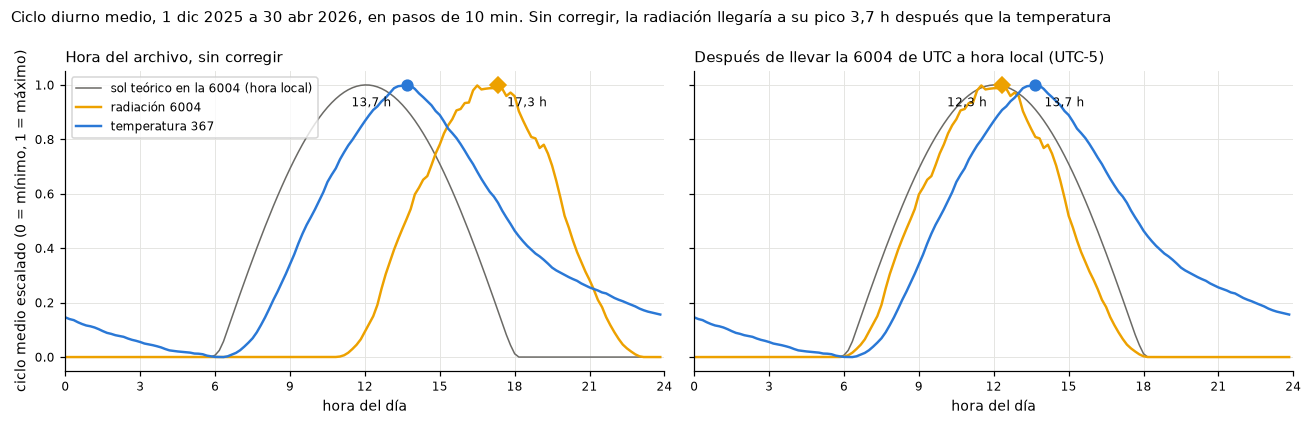

In [17]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
horas = lambda c: c.index / 60
for eje, (clave, titulo) in zip(ejes, [("archivo", "Hora del archivo, sin corregir"),
                                        ("local", "Después de llevar la 6004 de UTC a hora local (UTC-5)")]):
    sol_c = ciclo(cos_z)
    eje.plot(horas(sol_c), sol_c, color=GRIS, lw=1, label="sol teórico en la 6004 (hora local)")
    series = [("6004", ciclos[clave], "radiación 6004"), ("367", ciclo(t367), "temperatura 367")]
    primero = min(series, key=lambda x: pico(x[1]))[0]  # la etiqueta del pico más temprano va a la izquierda
    for c, s, nombre in series:
        eje.plot(horas(s), s, color=COLOR[c], label=nombre)
        eje.plot(pico(s), 1, marker=MARCA[c], ms=7, color=COLOR[c])
        eje.annotate(f"{coma(pico(s))} h", (pico(s), 1), xytext=(-36 if c == primero else 6, -14),
                     textcoords="offset points", fontsize=8)
    eje.set_xticks(range(0, 25, 3))
    eje.set_xlim(0, 24)
    eje.set_xlabel("hora del día")
    eje.set_title(titulo)
ejes[0].set_ylabel("ciclo medio escalado (0 = mínimo, 1 = máximo)")
ejes[0].legend(loc="upper left")
atraso = pico(ciclos["archivo"]) - pico(ciclo(t367))
fig.suptitle(f"Ciclo diurno medio, 1 dic 2025 a 30 abr 2026, en pasos de 10 min. Sin corregir, la radiación llegaría "
             f"a su pico {coma(atraso)} h después que la temperatura", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
guardar(fig, "relojes")

Lectura de la sección 4:

- Sin corregir, el pico medio de radiación de la 6004 cae a las 17,3 h del archivo y el de temperatura de la 367 a las
  13,7 h: la temperatura llegaría a su máximo 3,7 h antes que el sol, lo que no tiene sentido físico. La correlación
  cruzada horaria da su máximo con la temperatura 3 h adelante de la radiación. Corregida a UTC-5, el pico de
  radiación queda en 12,3 h, junto al máximo teórico del sol (12,0 h), y la temperatura va 2 h detrás de la
  radiación (correlación 0,848, casi igual a 1 h con 0,830), que es lo esperable.
- Si el archivo estuviera en hora local, 63 861 minutos superarían la radiación extraterrestre; leído como UTC, 1162.
  De esos 1162, 550 son luz de crepúsculo con el sol todavía bajo el horizonte (la extraterrestre vale 0) y 612 tienen
  el sol arriba; los que tienen el sol a más de 5° son episodios cortos con nubes alrededor, compatibles con realce
  por nubes (notebook 03).
- La regla 1582 de SIATA funciona en hora local sobre este archivo en UTC: marca los 952 minutos con radiación mayor
  que 0 entre las 18:00 y las 05:59 hora local (con el minuto de las 06:00 son los 977 de 977, notebook 03). Si trabajara con el reloj del archivo, marcaría también la tarde
  soleada (44 971 minutos con radiación en esa ventana del archivo), y solo 832 de ellos (1,9 %) tienen 1582. El
  sistema de SIATA sabe que la 6004 está en UTC (lo dice la guía de piranómetros, P-GAA-SIATA-111, p. 3), pero el archivo publicado no lo dice.
- La 367 y la 35 están en el mismo reloj al minuto: la lluvia minutal correlaciona 0,883 sin desfase y baja a 0,83 con
  un minuto de corrimiento; a 5 minutos, 0,973 sin desfase.
- De las 15 marcas con segundos de la 6004, 12 caen el domingo entre las 22:01 y las 22:03 hora local (lunes 03:01 a
  03:03 UTC), y dos de las otras tres son el primer registro después de un hueco (31 dic y 9 abr, fin del hueco de
  1752 minutos). Parece una tarea semanal del registrador y la reconexión después de una caída (inferido).

## 5. Lluvia de la 367 frente a la 35 en el mismo sitio

La 367 (`p`, resolución 0,01 mm) y la 35 (`p1` y `p2`, balancines de 0,254 mm) tienen las mismas coordenadas. Si
midieran lo mismo, sus acumulados coincidirían. Se comparan con: totales mensuales con los minutos sin dato a la
vista, regresión por el origen en días completos, curva de doble masa, concordancia de ocurrencia con el mismo umbral,
y dos pruebas nuevas para saber si la diferencia es un factor fijo (unidades o configuración) o depende de la lluvia:
la razón por clase de intensidad horaria y la razón por evento.

In [18]:
p, p1, p2 = lluvia["p"], lluvia["p1"], lluvia["p2"]
minutos_mes = p.resample("MS").size()
mensual_lluvia = pd.DataFrame({"p (367)": p.resample("MS").sum(), "p1 (35)": p1.resample("MS").sum(),
                               "p2 (35)": p2.resample("MS").sum(),
                               "min sin dato 367": minutos_mes - p.resample("MS").count(),
                               "min sin dato 35": minutos_mes - p1.resample("MS").count()})
mensual_lluvia.loc["total"] = mensual_lluvia.sum()
mensual_lluvia["p / p1"] = mensual_lluvia["p (367)"] / mensual_lluvia["p1 (35)"]
mensual_lluvia.round(3)

,p (367),p1 (35),p2 (35),min sin dato 367,min sin dato 35,p / p1
fecha_hora,,,,,,
2025-12-01 00:00:00,36.92,109.220,115.062,11,0,0.338
2026-01-01 00:00:00,72.98,247.396,244.856,18,6,0.295
2026-02-01 00:00:00,45.10,141.478,143.510,8,0,0.319
2026-03-01 00:00:00,50.35,151.130,152.654,6,1,0.333
2026-04-01 00:00:00,63.25,198.882,202.184,0,0,0.318
total,268.60,848.106,858.266,43,7,0.317


In [19]:
diaria = pd.DataFrame({"p": p.resample("D").sum(), "p1": p1.resample("D").sum(),
                       "n_p": p.resample("D").count(), "n_p1": p1.resample("D").count()})
completos = diaria[(diaria.n_p == 1440) & (diaria.n_p1 == 1440)]
pendiente = (completos.p * completos.p1).sum() / (completos.p1 ** 2).sum()  # p = b·p1, sin intercepto
print(f"días con los 1440 minutos en ambas estaciones: {len(completos)} de {len(diaria)}")
print(f"correlación diaria p~p1: {completos.p.corr(completos.p1):.3f} | Spearman: {spearmanr(completos.p, completos.p1).statistic:.3f}")
print(f"regresión por el origen: p = {pendiente:.3f} · p1")

# Ocurrencia en horas completas con el umbral del balancín para los dos sensores
H = lluvia.resample("h").sum(min_count=60).dropna()
UMBRAL = 0.254
display(pd.crosstab(H.p >= UMBRAL, H.p1 >= UMBRAL, rownames=["367 ≥ 0,254 mm"], colnames=["35 ≥ 0,254 mm"]))
solo_367 = (H.p > 0) & (H.p1 == 0)
print(f"horas completas: {len(H)} | con lluvia en la 367 y cero en la 35: {solo_367.sum()} "
      f"({H.p[solo_367].sum():.1f} mm, máximo {H.p[solo_367].max():.2f} mm en una hora)")
print(f"p1 frente a p2: totales {p1.sum():.1f} y {p2.sum():.1f} mm, correlación horaria {H.p1.corr(H.p2):.3f}")
print(f"máximo en un minuto: 367 {p.max():.2f} mm, 35 {p1.max():.3f} mm | máximo en 10 min: "
      f"367 {p.resample('10min').sum().max():.2f} mm, 35 {p1.resample('10min').sum().max():.2f} mm")

días con los 1440 minutos en ambas estaciones: 142 de 151
correlación diaria p~p1: 0.986 | Spearman: 0.958
regresión por el origen: p = 0.283 · p1


"35 ≥ 0,254 mm",False,True
"367 ≥ 0,254 mm",,
False,3289,123
True,4,190


horas completas: 3606 | con lluvia en la 367 y cero en la 35: 423 (18.4 mm, máximo 0.35 mm en una hora)
p1 frente a p2: totales 848.1 y 858.3 mm, correlación horaria 0.998
máximo en un minuto: 367 0.52 mm, 35 2.286 mm | máximo en 10 min: 367 3.32 mm, 35 14.99 mm


In [20]:
# Razón p/p1 por clase de intensidad horaria. La clase se define con p2 y la razón se calcula contra p1, para que
# el error de cuantización del balancín que asigna la clase no sea el mismo del denominador (regresión a la media).
CLASES = [0, 0.254, 1, 2.5, 5, 10, np.inf]
ETIQUETAS = ["hasta 0,254", "0,254 a 1", "1 a 2,5", "2,5 a 5", "5 a 10", "más de 10"]
lluviosas = H[H.p2 > 0].assign(clase=lambda d: pd.cut(d.p2, CLASES, labels=ETIQUETAS),
                               clase_p1=lambda d: pd.cut(d.p1, CLASES, labels=ETIQUETAS))
por_clase = lluviosas.groupby("clase", observed=False).agg(horas=("p", "size"), p_367=("p", "sum"), p1_35=("p1", "sum"),
                                                           horas_367_en_cero=("p", lambda s: (s == 0).sum()))
por_clase["razón"] = por_clase.p_367 / por_clase.p1_35
alterna = H[H.p1 > 0].assign(clase=lambda d: pd.cut(d.p1, CLASES, labels=ETIQUETAS)).groupby("clase", observed=False)
por_clase["razón si la clase sale de p1"] = alterna.p.sum() / alterna.p1.sum()

# Intervalo de 95 % con bootstrap por días (las horas de un mismo día no son independientes)
rng = np.random.default_rng(2026)
dia = lluviosas.index.normalize()
S = lluviosas.groupby([dia, "clase"], observed=False)[["p", "p1"]].sum().unstack("clase")
P, P1 = S["p"].to_numpy(), S["p1"].to_numpy()
muestras = rng.integers(0, len(S), size=(2000, len(S)))
boot = P[muestras].sum(axis=1) / P1[muestras].sum(axis=1)
por_clase["IC95 bajo"], por_clase["IC95 alto"] = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
print(f"días con lluvia en la muestra: {len(S)} | Spearman entre lluvia horaria de la 35 (p2) y razón p/p1 por hora "
      f"(horas con p1 > 0): {spearmanr(lluviosas.p2[lluviosas.p1 > 0], (lluviosas.p / lluviosas.p1)[lluviosas.p1 > 0]).statistic:.3f}")
por_clase.round(3)

días con lluvia en la muestra: 94 | Spearman entre lluvia horaria de la 35 (p2) y razón p/p1 por hora (horas con p1 > 0): -0.581


,horas,p_367,p1_35,horas_367_en_cero,razón,razón si la clase sale de p1,IC95 bajo,IC95 alto
clase,,,,,,,,
"hasta 0,254",95,9.73,16.510,25,0.589,0.504,0.495,0.709
"0,254 a 1",74,20.34,39.624,0,0.513,0.468,0.476,0.554
"1 a 2,5",70,35.21,103.378,2,0.341,0.348,0.301,0.380
"2,5 a 5",36,43.20,137.668,0,0.314,0.317,0.295,0.330
5 a 10,24,48.48,174.752,0,0.277,0.274,0.258,0.301
más de 10,20,89.19,355.600,0,0.251,0.250,0.243,0.258


In [21]:
# Razón por evento: bloques de lluvia en la 35 separados por al menos 2 h secas, con 5 mm o más
minutos_lluvia = p1[p1 > 0]
evento = (minutos_lluvia.index.to_series().diff() > pd.Timedelta("2h")).cumsum().to_numpy()
eventos = pd.DataFrame({"inicio": minutos_lluvia.index.to_series().groupby(evento).min(),
                        "fin": minutos_lluvia.index.to_series().groupby(evento).max(),
                        "lluvia 35 (mm)": minutos_lluvia.groupby(evento).sum()})
eventos = eventos[eventos["lluvia 35 (mm)"] >= 5].reset_index(drop=True)
r10 = p1.resample("10min").sum(min_count=1)
eventos["duración (min)"] = (eventos.fin - eventos.inicio) / pd.Timedelta("1min") + 1
eventos["lluvia 367 (mm)"] = [p[e.inicio:e.fin].sum() for e in eventos.itertuples()]
eventos["min sin dato 367"] = [int(p[e.inicio:e.fin].isna().sum()) for e in eventos.itertuples()]
eventos["intensidad media (mm/h)"] = eventos["lluvia 35 (mm)"] / eventos["duración (min)"] * 60
eventos["máx 10 min 35 (mm)"] = [r10[e.inicio:e.fin].max() for e in eventos.itertuples()]
eventos["viento medio 367 (m/s)"] = [m367["vv"][e.inicio:e.fin].mean() for e in eventos.itertuples()]
eventos["razón"] = eventos["lluvia 367 (mm)"] / eventos["lluvia 35 (mm)"]
print(f"eventos: {len(eventos)} | razón mediana {eventos['razón'].median():.3f} (mín {eventos['razón'].min():.3f}, "
      f"máx {eventos['razón'].max():.3f}) | eventos con minutos sin dato en la 367: {(eventos['min sin dato 367'] > 0).sum()}")
for col in ["intensidad media (mm/h)", "máx 10 min 35 (mm)", "lluvia 35 (mm)", "duración (min)", "viento medio 367 (m/s)"]:
    r = spearmanr(eventos[col], eventos["razón"])
    print(f"Spearman razón ~ {col}: {r.statistic:.3f} (p = {r.pvalue:.4f})")
eventos.sort_values("lluvia 35 (mm)", ascending=False).head(10).round({c: 3 for c in eventos.columns if c not in ("inicio", "fin")})

eventos: 49 | razón mediana 0.272 (mín 0.200, máx 0.389) | eventos con minutos sin dato en la 367: 2
Spearman razón ~ intensidad media (mm/h): -0.582 (p = 0.0000)
Spearman razón ~ máx 10 min 35 (mm): -0.508 (p = 0.0002)
Spearman razón ~ lluvia 35 (mm): -0.427 (p = 0.0022)
Spearman razón ~ duración (min): 0.294 (p = 0.0405)
Spearman razón ~ viento medio 367 (m/s): -0.156 (p = 0.2831)


,inicio,fin,lluvia 35 (mm),duración (min),lluvia 367 (mm),min sin dato 367,intensidad media (mm/h),máx 10 min 35 (mm),viento medio 367 (m/s),razón
39,2026-04-03 16:02:00,2026-04-03 17:12:00,43.434,71.0,10.89,0,36.705,13.970,2.313,0.251
19,2026-01-26 22:12:00,2026-01-27 01:20:00,36.830,189.0,9.88,0,11.692,7.366,0.727,0.268
24,2026-02-06 00:55:00,2026-02-06 07:08:00,35.814,374.0,9.90,0,5.746,8.890,0.663,0.276
42,2026-04-16 01:50:00,2026-04-16 07:20:00,34.544,331.0,10.11,0,6.262,11.938,0.689,0.293
14,2026-01-12 09:07:00,2026-01-12 11:21:00,29.210,135.0,7.57,0,12.982,6.604,0.521,0.259
38,2026-03-27 09:53:00,2026-03-27 13:14:00,27.686,202.0,6.47,0,8.224,14.986,1.302,0.234
43,2026-04-16 19:48:00,2026-04-17 01:01:00,26.924,314.0,6.97,0,5.145,2.286,0.660,0.259
31,2026-03-05 13:58:00,2026-03-05 15:21:00,22.606,84.0,4.52,0,16.147,12.446,2.890,0.200
0,2025-12-01 00:00:00,2025-12-01 03:33:00,21.336,214.0,7.27,0,5.982,3.556,0.801,0.341
47,2026-04-27 14:47:00,2026-04-27 17:12:00,21.082,146.0,5.52,0,8.664,8.636,1.472,0.262


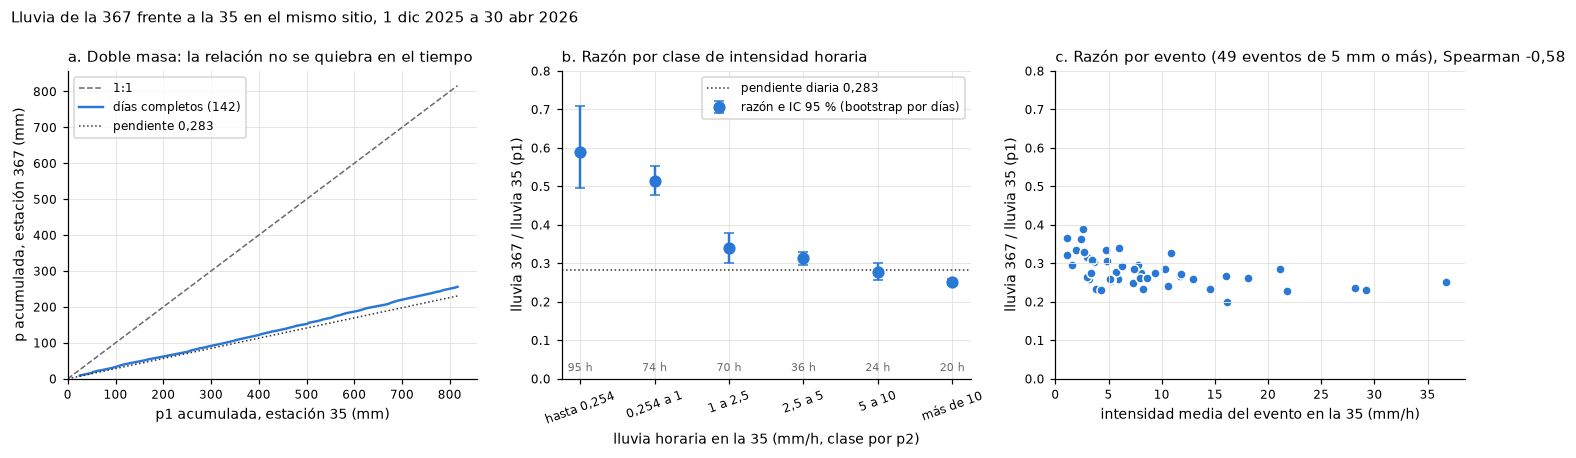

In [22]:
fig, ejes = plt.subplots(1, 3, figsize=(13.5, 4.2))
acum = completos[["p", "p1"]].cumsum()
tope = acum.p1.max()
ejes[0].plot([0, tope], [0, tope], color=GRIS, lw=1, ls="--", label="1:1")
ejes[0].plot(acum.p1, acum.p, color=COLOR["367"], label=f"días completos ({len(completos)})")
ejes[0].plot([0, tope], [0, pendiente * tope], color="#333333", lw=1, ls=":", label=f"pendiente {coma(pendiente, 3)}")
ejes[0].set(xlabel="p1 acumulada, estación 35 (mm)", ylabel="p acumulada, estación 367 (mm)", xlim=(0, None), ylim=(0, None))
ejes[0].set_title("a. Doble masa: la relación no se quiebra en el tiempo")
ejes[0].legend(loc="upper left")

xc = np.arange(len(por_clase))
ejes[1].errorbar(xc, por_clase["razón"], yerr=[por_clase["razón"] - por_clase["IC95 bajo"], por_clase["IC95 alto"] - por_clase["razón"]],
                 fmt="o", ms=7, color=COLOR["367"], ecolor=COLOR["367"], capsize=3, label="razón e IC 95 % (bootstrap por días)")
ejes[1].axhline(pendiente, color="#333333", lw=1, ls=":", label=f"pendiente diaria {coma(pendiente, 3)}")
for xi, n in zip(xc, por_clase["horas"]):
    ejes[1].annotate(f"{n} h", (xi, 0.02), ha="center", fontsize=7, color=GRIS)
ejes[1].set_xticks(xc, por_clase.index, rotation=20)
ejes[1].set(xlabel="lluvia horaria en la 35 (mm/h, clase por p2)", ylabel="lluvia 367 / lluvia 35 (p1)", ylim=(0, 0.8))
ejes[1].set_title("b. Razón por clase de intensidad horaria")
ejes[1].legend(loc="upper right")

ejes[2].scatter(eventos["intensidad media (mm/h)"], eventos["razón"], s=36, color=COLOR["367"], edgecolor="white", linewidth=1)
rho = spearmanr(eventos["intensidad media (mm/h)"], eventos["razón"]).statistic
ejes[2].set(xlabel="intensidad media del evento en la 35 (mm/h)", ylabel="lluvia 367 / lluvia 35 (p1)", ylim=(0, 0.8), xlim=(0, None))
ejes[2].set_title(f"c. Razón por evento ({len(eventos)} eventos de 5 mm o más), Spearman {coma(rho, 2)}")
fig.suptitle("Lluvia de la 367 frente a la 35 en el mismo sitio, 1 dic 2025 a 30 abr 2026", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
guardar(fig, "lluvia_367_vs_35")

Lectura de la sección 5:

- La 367 registra 268,6 mm en el periodo y la 35 848,1 mm (p1) y 858,3 mm (p2). En días completos la relación es
  p = 0,283·p1 con correlación diaria de 0,986. Todos los días con lluvia en la 35 tienen lluvia en la 367, y la 367 suma días de llovizna que la 35 no ve; en los días con lluvia en las dos, lo que cambia es la
  cantidad. La razón de totales es 0,317 y la pendiente 0,283: la regresión pesa más los días de mucha lluvia, y en
  esos días la razón es menor (ver el punto siguiente).
- La razón no se mueve en el tiempo: los meses van de 0,30 a 0,34 sin tendencia y la curva de doble masa es una recta
  sin quiebres. No hubo un cambio de sensor o de configuración visible dentro del periodo.
- La razón sí depende de la intensidad. En horas con lluvia débil (0,254 a 1 mm/h en la 35) la 367 registra cerca de
  la mitad (0,51, IC 95 % 0,48 a 0,55); con más de 10 mm/h registra la cuarta parte (0,25, IC 0,24 a 0,26), y los
  intervalos no se tocan. Da casi lo mismo si la clase se define con p1 o con p2. Por eventos pasa igual: la razón
  baja con la intensidad media del evento (Spearman -0,58, p < 0,001) y no tiene relación clara con el viento (-0,16,
  p = 0,28). El máximo en 10 minutos lo muestra de otra forma: 3,32 mm en la 367 frente a 14,99 mm en la 35.
- Con el mismo umbral de 0,254 mm por hora, hay 123 horas en que la 35 lo supera y la 367 no, y solo 4 al revés. Pero
  hay 423 horas con algo de lluvia en la 367 y cero en la 35 (18,4 mm en total, máximo 0,35 mm en una hora): la 367
  ve lloviznas que no alcanzan a voltear el balancín.

Posibles causas (todas inferidas; no hay ficha técnica del sensor de lluvia de la 367 en los datos):

1. Unidades: descartada como causa única. Un error de unidades da un factor fijo y conocido (0,1 entre cm y mm, 0,039
   entre pulgadas y mm), y aquí el factor cambia con la intensidad de 0,5 a 0,25.
2. Configuración (constante de calibración o área del colector mal puesta): también daría un factor fijo. Puede
   explicar parte del nivel, pero no la caída con la intensidad.
3. Sensor de otro tipo: la resolución de 0,01 mm, los valores casi continuos (0,01, 0,02, 0,03 mm por minuto) y el
   juego de variables de la 367 (h, t, pr, vv, dv, p) son típicos de una estación compacta con sensor de lluvia por
   impacto, no de un balancín. Un sensor de impacto estima la lluvia a partir de las gotas que golpean una superficie,
   y su error depende del tamaño de gota, que cambia con la intensidad. Es la explicación más coherente con los
   datos, pero hay que confirmarla con la hoja de vida de la estación.
4. ¿Y si la que está mal es la 35? Tiene dos balancines independientes que coinciden (correlación horaria 0,998,
   totales a 1 % uno del otro). Los balancines tienden a perder agua con lluvia intensa, lo que haría subir la razón
   con la intensidad, y pasa lo contrario. Por eso se toma la 35 como referencia de cantidad.

Así, la `p` de la 367 sirve para detectar si llueve (ve más horas de llovizna que la 35), pero no
para acumulados, intensidades ni umbrales de alerta, y no se puede corregir con un factor único.

## 6. Lluvia de la 35 y nivel de la 803 por eventos

La 803 está a unos 240 m de la 35, en la quebrada La Aguadita. Aquí se resume la respuesta del nivel a los mismos 49
eventos de la sección 5. La correlación cruzada con rezagos, desestacionalizada, está en el notebook 08.

In [23]:
nivel = m803["nivel"]
variantes = {"solo calidad 1 de SIATA": nivel.where(m803["calidad"] == 1),
             "solo bandera propia buena": nivel.where(m803["b_nivel"] == 1)}
filas = []
for _, e in eventos.iterrows():
    fila = {"inicio": e["inicio"], "lluvia 35 (mm)": round(e["lluvia 35 (mm)"], 1), "máx 10 min 35 (mm)": e["máx 10 min 35 (mm)"]}
    for nombre, n_ok in variantes.items():
        base = n_ok[e["inicio"] - pd.Timedelta("1h"): e["inicio"]].median()
        ventana = n_ok[e["inicio"]: e["fin"] + pd.Timedelta("3h")]
        pico = ventana.idxmax() if ventana.notna().any() else pd.NaT
        fila[f"subida, {nombre} (cm)"] = round(ventana.max() - base, 1)
        fila[f"min al pico, {nombre}"] = (pico - e["inicio"]) / pd.Timedelta("1min") if pd.notna(pico) else np.nan
    fila["% registros con calidad ≠ 1"] = round(100 * (m803["calidad"][e["inicio"]: e["fin"] + pd.Timedelta("3h")] != 1).mean(), 1)
    filas.append(fila)
respuesta = pd.DataFrame(filas)
for nombre in variantes:
    v = respuesta.dropna(subset=[f"subida, {nombre} (cm)"])
    print(f"{nombre}: {len(v)} eventos con nivel | Spearman lluvia ~ subida "
          f"{spearmanr(v['lluvia 35 (mm)'], v[f'subida, {nombre} (cm)']).statistic:.3f} | Spearman máx 10 min ~ subida "
          f"{spearmanr(v['máx 10 min 35 (mm)'], v[f'subida, {nombre} (cm)']).statistic:.3f} | mediana de minutos al pico "
          f"{v[f'min al pico, {nombre}'].median():.0f}")
print("mediana de % de registros con calidad ≠ 1 en la ventana de los eventos:", respuesta["% registros con calidad ≠ 1"].median())
respuesta.sort_values("lluvia 35 (mm)", ascending=False).head(10)

solo calidad 1 de SIATA: 49 eventos con nivel | Spearman lluvia ~ subida 0.424 | Spearman máx 10 min ~ subida 0.400 | mediana de minutos al pico 20
solo bandera propia buena: 48 eventos con nivel | Spearman lluvia ~ subida 0.442 | Spearman máx 10 min ~ subida 0.396 | mediana de minutos al pico 26
mediana de % de registros con calidad ≠ 1 en la ventana de los eventos: 0.9


,inicio,lluvia 35 (mm),máx 10 min 35 (mm),"subida, solo calidad 1 de SIATA (cm)","min al pico, solo calidad 1 de SIATA","subida, solo bandera propia buena (cm)","min al pico, solo bandera propia buena",% registros con calidad ≠ 1
39,2026-04-03 16:02:00,43.4,13.970,26.2,28.0,26.2,28.0,5.2
19,2026-01-26 22:12:00,36.8,7.366,6.1,105.0,6.1,105.0,0.5
24,2026-02-06 00:55:00,35.8,8.890,11.2,80.0,11.2,80.0,0.0
42,2026-04-16 01:50:00,34.5,11.938,11.2,229.0,11.2,229.0,0.0
14,2026-01-12 09:07:00,29.2,6.604,9.4,21.0,9.4,21.0,0.0
38,2026-03-27 09:53:00,27.7,14.986,33.7,24.0,33.7,24.0,1.0
43,2026-04-16 19:48:00,26.9,2.286,3.7,289.0,3.7,289.0,0.0
31,2026-03-05 13:58:00,22.6,12.446,9.7,16.0,9.7,16.0,0.0
0,2025-12-01 00:00:00,21.3,3.556,3.4,18.0,NaN,172.0,1.5
47,2026-04-27 14:47:00,21.1,8.636,3.5,5.0,3.5,5.0,4.6


In [24]:
# ¿Los registros que SIATA marca 151 o 251 en la 803 coinciden con lluvia? Si no llovió antes, no son crecientes
lluvia_3h = p1.fillna(0).rolling("3h").sum()
marcas = m803[m803["presente"]].assign(lluvia_3h=lluvia_3h.reindex(m803.index[m803["presente"]]).to_numpy())
marcas["sin lluvia en las 3 h previas"] = marcas["lluvia_3h"] == 0
marcas["nivel > 50 cm"] = marcas["nivel"] > 50
alto = marcas["nivel > 50 cm"]
print(f"nivel máximo con calidad 1: {marcas.loc[marcas['calidad'] == 1, 'nivel'].max():.1f} cm | minutos con nivel > 50 cm: "
      f"{int(alto.sum())}, de ellos sin lluvia en las 3 h previas: {marcas.loc[alto, 'sin lluvia en las 3 h previas'].mean():.1%}")
marcas.groupby("calidad").agg(registros=("nivel", "size"), nivel_mediano_cm=("nivel", "median"),
                              sobre_50_cm=("nivel > 50 cm", "mean"),
                              sin_lluvia_previa=("sin lluvia en las 3 h previas", "mean")).round(3)

nivel máximo con calidad 1: 36.2 cm | minutos con nivel > 50 cm: 5044, de ellos sin lluvia en las 3 h previas: 91.6%


,registros,nivel_mediano_cm,sobre_50_cm,sin_lluvia_previa
calidad,,,,
1.0,191042,2.6,0.000,0.822
2.0,42,5.2,0.000,0.452
151.0,7955,164.9,0.585,0.945
251.0,394,157.7,1.000,0.997
1502.0,14333,4.5,0.000,0.929
1504.0,2987,-0.5,0.000,0.954
2502.0,565,8.6,0.000,0.995


Lectura de la sección 6:

- El nivel responde a la lluvia de la 35 con una mediana de 20 minutos al pico (26 con la bandera propia), coherente
  con una cuenca pequeña y estaciones a 240 m. La relación entre la lluvia del evento y la subida es moderada
  (Spearman 0,424 con calidad 1 y 0,442 con la bandera propia); con la intensidad máxima en 10 minutos da parecido
  (0,40). Que el filtro no cambie la conclusión indica que no depende de confiar en `calidad`. La subida también
  depende de la humedad previa de la cuenca y del punto exacto donde cae la lluvia, que estos datos no tienen.
- El nivel máximo con código 1 es 36,2 cm. Hay 5044 minutos con más de 50 cm y el 91,6 % no tiene lluvia en la 35 en
  las 3 h previas. Los 151 y 251 son justamente esos niveles (mediana 164,9 y 157,7 cm; 94,5 % y 99,7 % sin lluvia
  previa). La falta de lluvia previa sola no discrimina, porque el 82,2 % de los registros con código 1 tampoco la
  tiene (casi siempre está seco); lo que discrimina es nivel alto sin lluvia. Son mesetas sin
  causa hidrológica en los datos (falla de sensor o del canal, inferido). Este cruce entre estaciones es la prueba
  más fuerte para clasificarlos, y por eso la regla propia `pico_sin_lluvia` usa la 35.

## 7. Distancia entre estaciones

Distancia sobre la esfera (haversine) con las coordenadas guardadas en `siata.datos.ESTACIONES` (caja geográfica de cada registro en
datos.siata.gov.co). Esas latitudes quedan 0,0001°, unos 11 m, al norte de las de las tablas de estaciones de SIATA
en las cuatro estaciones (en la 6004, 6,406712 frente a 6,406612 de la ficha); como el corrimiento es igual en todas,
las distancias no cambian. Solo la ficha de la 6004 trae altitud (1355 msnm); para las demás no hay dato verificado.

In [25]:
def distancia_km(a, b):
    la1, lo1, la2, lo2 = map(np.radians, [ESTACIONES[a]["lat"], ESTACIONES[a]["lon"], ESTACIONES[b]["lat"], ESTACIONES[b]["lon"]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(h))

distancias = pd.DataFrame({a: {b: distancia_km(a, b) for b in ESTACIONES} for a in ESTACIONES}).round(3)
distancias.index.name = "km"
display(distancias)
pd.DataFrame({c: {"nombre": ESTACIONES[c]["nombre"], "lat": ESTACIONES[c]["lat"], "lon": ESTACIONES[c]["lon"]} for c in ESTACIONES}).T

,367,803,6004,35
km,,,,
367,0.000,0.242,21.644,0.000
803,0.242,0.000,21.884,0.242
6004,21.644,21.884,0.000,21.644
35,0.000,0.242,21.644,0.000


,nombre,lat,lon
367,"Joaquín Vallejo (La Ladera, Medellín)",6.255345,-75.542478
803,"Q. La Aguadita, Colinas de Enciso (Medellín)",6.25385,-75.544067
6004,Parque de las Aguas (Barbosa),6.406712,-75.419344
35,"I.E. Joaquín Vallejo Arbeláez (La Ladera, Mede...",6.255345,-75.542478


Lectura de la sección 7:

- La 367 y la 35 comparten coordenadas (0 m en la ficha): se pueden usar como pareja redundante de lluvia, con la
  diferencia de sensor de la sección 5. Que compartan coordenadas no dice que estén a la misma altura ni con la
  misma exposición, y eso no está documentado.
- La 803 está a 0,24 km de las dos. Sirve para la prueba espacial lluvia-nivel (sección 6), pero el pluviómetro no
  está en la cuenca exacta del punto de medición de nivel, así que la relación es indicativa.
- La 6004 está a 21,6 km al noreste, en Barbosa, y su ficha la da como inactiva. A esa distancia no sirve como vecina
  para la coherencia espacial de la 367 (además no comparten variables), y su ciclo diurno solo se usó para el reloj
  (sección 4), donde lo que importa es la posición del sol, casi igual en los dos sitios.

## 8. Hallazgos comparativos priorizados

Prioridad según el impacto en el uso del dato (alertas y acumulados primero) y lo fácil que es corregirlo.

| # | Problema | Evidencia | Impacto | Recomendación |
|---|---|---|---|---|
| 1 | La lluvia de la 367 registra el 32 % del total de la 35 en el mismo sitio (268,6 frente a 848,1 mm), y la razón depende de la intensidad | p = 0,283·p1 en días completos; razón 0,51 con 0,254 a 1 mm/h y 0,25 con más de 10 mm/h (IC 95 % sin traslape); Spearman -0,58 con la intensidad del evento; máximo en 10 min de 3,32 frente a 14,99 mm | Un usuario que tome la `p` de la 367 subestima acumulados y, sobre todo, aguaceros fuertes, que son los que importan para alertas | No publicar la `p` de la 367 como cantidad sin advertencia; usar la 35 como referencia; revisar en campo tipo de sensor y configuración; no corregir con un factor único |
| 2 | El diccionario de `calidad` está en guías aparte por red, no en la ficha de la estación, y sus reglas cambian durante el periodo | 1504 marca 2987 de 2988 negativos en diciembre y ninguno de 8692 después; 1511 de la 367 no aparece en diciembre (307 casos) y luego marca 13 % a 46 %; 154 solo en enero y febrero; kappa con el control propio de 0,008 a 0,068 en tres estaciones | Filtrar por `calidad` da resultados distintos según el mes, y no se sabe qué versión del algoritmo marcó cada dato | Publicar el diccionario de códigos por estación y la versión del algoritmo con cada dato; mientras tanto, tratar `calidad` como etiqueta débil |
| 3 | La 6004 viene en UTC y las otras tres en hora local, sin que el archivo lo diga | Pico de radiación a las 17,3 h del archivo frente a 12,3 h corregido; 63 861 frente a 1162 minutos sobre la extraterrestre; la regla 1582 de SIATA funciona en hora local | Cualquier cruce entre estaciones o análisis de ciclo diurno con la 6004 sin corregir queda corrido 5 horas | Publicar las marcas en ISO 8601 con desfase (por ejemplo, -05:00) y declarar la zona horaria en los metadatos de cada estación |
| 4 | Una misma falla común se guarda de dos formas | Los 7 minutos con -999 (código 151) de la 35 son minutos sin fila en la 367 (7 de 7) y en la 803 (6 de 7) | Contar faltantes solo por filas ausentes da 100 % de completitud a la 35; el -999 sin tratar mete valores imposibles en sumas | Una sola convención para faltantes en todos los archivos: fila presente, valor vacío y bandera de faltante |
| 5 | La 6004 es el conjunto con más huecos y su ficha dice "inactiva" | 2617 minutos sin registro, 207 huecos, uno de 1752 min (8 y 9 abr); 4,25 % sin dato en abril; ficha actualizada en 2024 | Completitud aceptable en el periodo, pero es la estación que primero cae al semáforo de alerta; metadatos contradictorios | Corregir el estado en la ficha y vigilar la completitud mensual de la 6004 |
| 6 | Las mesetas de nivel que SIATA marca 151 y 251 en la 803 no tienen lluvia que las explique | Nivel máximo con código 1 de 36,2 cm; 5044 minutos sobre 50 cm, el 91,6 % sin lluvia en la 35 en las 3 h previas; válidos de la 803 en 90,8 % en diciembre y 91,5 % en marzo | Si se toman como crecientes, inflan estadísticas de nivel y pueden disparar falsas alertas | Mantener la prueba espacial lluvia-nivel; revisar en campo el sensor de la 803 en esas fechas |
| 7 | La resolución de una misma variable cambia entre estaciones | Lluvia en pasos de 0,01 mm (367) y 0,254 mm (35); nivel en pasos de 0,1 cm guardado en float32 (valores como 2,700012) | Umbrales de ocurrencia y reglas de resolución no se pueden copiar de una estación a otra | Declarar la resolución de cada sensor en el diccionario; comparar con el umbral del sensor más grueso |

## Figura para el resumen ejecutivo

Estado de la red en el periodo con los tres indicadores de la pregunta 1.3. Cada celda lleva valor, ícono y texto del estado para no depender del color. En las estaciones con varias variables se muestra la peor.

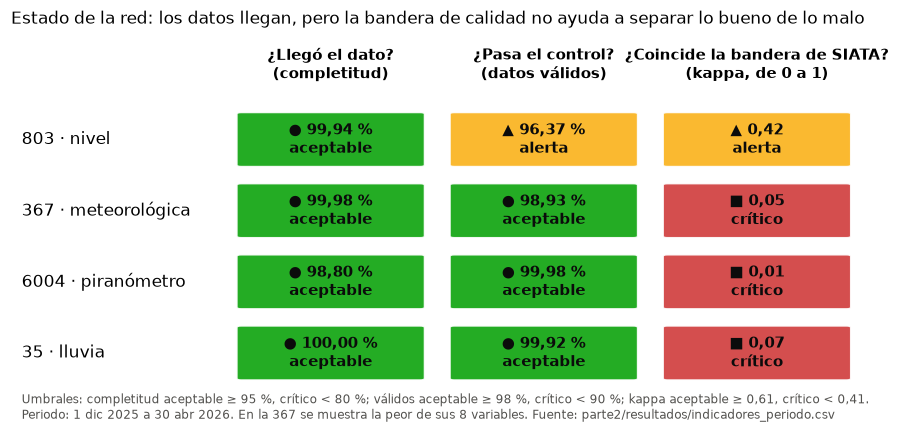

In [26]:
from siata import indicadores as I
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

per = pd.read_csv(RAIZ / "parte2" / "resultados" / "indicadores_periodo.csv", dtype={"codigo": str})
peor = per.groupby("codigo").agg(completitud=("completitud", "min"), validos=("validos", "min"),
                                 kappa=("kappa", "first")).reindex(["803", "367", "6004", "35"])
nombres = {"803": "803 · nivel", "367": "367 · meteorológica", "6004": "6004 · piranómetro", "35": "35 · lluvia"}
columnas = [("completitud", "¿Llegó el dato?\n(completitud)", lambda v: f"{100 * v:.2f} %".replace(".", ",")),
            ("validos", "¿Pasa el control?\n(datos válidos)", lambda v: f"{100 * v:.2f} %".replace(".", ",")),
            ("kappa", "¿Coincide la bandera de SIATA?\n(kappa, de 0 a 1)", lambda v: f"{v:.2f}".replace(".", ","))]
estilo = {"aceptable": ("#0ca30c", "●"), "alerta": ("#fab219", "▲"), "crítico": ("#d03b3b", "■")}
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(0, 4)
ax.set_ylim(0, 5)
ax.axis("off")
for j, (_, titulo, _) in enumerate(columnas):
    ax.text(1.5 + j, 4.55, titulo, ha="center", va="center", fontsize=10, weight="bold")
for i, codigo in enumerate(peor.index):
    y = 3.5 - i
    ax.text(0.05, y, nombres[codigo], va="center", fontsize=11)
    for j, (col, _, fmt) in enumerate(columnas):
        estado = I.semaforo(peor.loc[codigo, col], col)
        color, icono = estilo[estado]
        ax.add_patch(FancyBboxPatch((1.08 + j, y - 0.36), 0.84, 0.72, boxstyle="round,pad=0.02",
                                    fc=color, ec="white", alpha=0.9))
        ax.text(1.5 + j, y, f"{icono} {fmt(peor.loc[codigo, col])}\n{estado}", ha="center", va="center",
                fontsize=10, color="#0b0b0b", weight="bold")
ax.text(0.05, -0.05, "Umbrales: completitud aceptable ≥ 95 %, crítico < 80 %; válidos aceptable ≥ 98 %, crítico < 90 %; "
        "kappa aceptable ≥ 0,61, crítico < 0,41.\nPeriodo: 1 dic 2025 a 30 abr 2026. En la 367 se muestra la peor de "
        "sus 8 variables. Fuente: parte2/resultados/indicadores_periodo.csv", fontsize=8, color="#52514e", va="top")
ax.set_title("Estado de la red: los datos llegan, pero la bandera de calidad no ayuda a separar lo bueno de lo malo",
             fontsize=11, loc="left")
fig.savefig(RAIZ / "parte2" / "figuras" / "00_resumen_red.png", dpi=110, bbox_inches="tight")
plt.show()
